# Convolution fundamentals: from 1D signals to 2D images

<a target="_blank" href="https://colab.research.google.com/github/changyaochen/MECE4520/blob/master/site/neural-networks/03-convolution-basics.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/></a>

A convolutional neural network (CNN) starts with a simple idea: use a
small set of numbers—a **filter**—as a sliding local pattern detector.
The same filter is reused at every location. This notebook develops that
idea first for a one-dimensional signal, then for a two-dimensional image.

We use the convention employed by deep-learning libraries: the filter is
slid without reversing it. Strictly, that operation is cross-correlation,
but it is conventionally called *convolution* in CNNs.

## What you will do

1. Compute a 1D sliding dot product by hand and across a full signal.
2. See how different 1D filters respond to different local patterns.
3. Apply hand-designed 2D filters to a toy image to form feature maps.
4. Connect local receptive fields and weight sharing to a CNN.

## 1. A one-dimensional sliding filter

Suppose $x$ is a vibration or sensor signal and $w$ is a short filter.
At position $i$, the CNN-style 1D convolution response is a local dot
product:

$$
r_i = \sum_{k=0}^{K-1} w_k\,x_{i + k - \lfloor K/2 \rfloor}.
$$

The filter contains only $K$ trainable values, but it is reused at every
signal position. Below, a three-value edge filter responds strongly when
the signal changes locally.

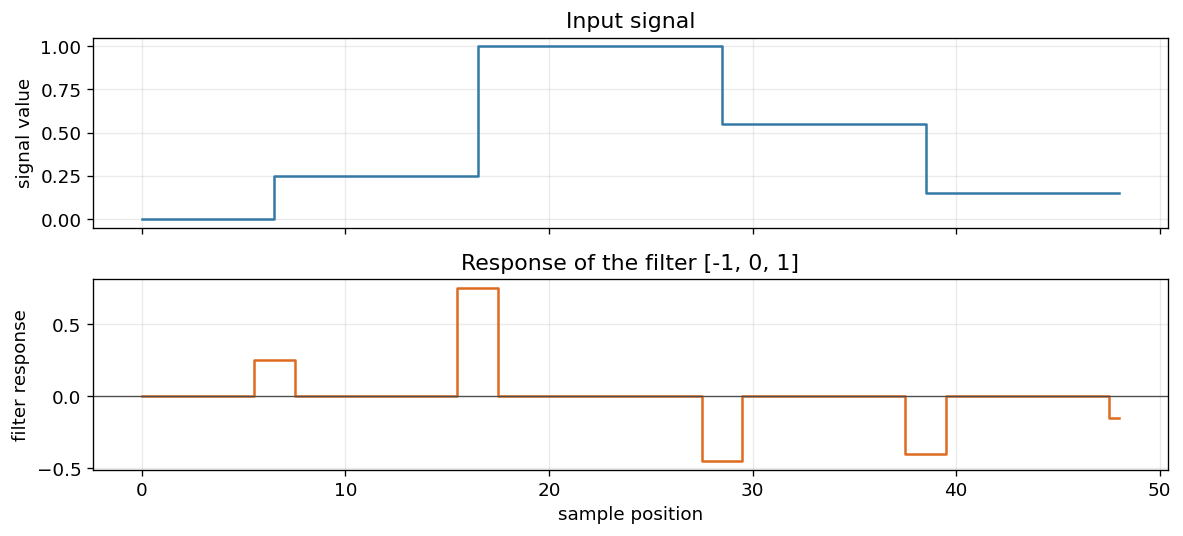

In [1]:
import matplotlib.pyplot as plt
import numpy as np


plt.rcParams.update({"figure.dpi": 120, "font.size": 11})


def same_cross_correlation_1d(*, signal: np.ndarray, kernel: np.ndarray) -> np.ndarray:
    """Apply an odd-length 1D filter at every signal position.

    Args:
        signal: One-dimensional input values with shape `(n_samples,)`.
        kernel: Odd-length filter values with shape `(kernel_size,)`.

    Returns:
        Filter response with the same shape as `signal`.

    Raises:
        ValueError: If the filter does not have odd length.
    """
    if kernel.size % 2 == 0:
        raise ValueError("Use an odd-length filter so it has a center.")

    radius = kernel.size // 2
    padded_signal = np.pad(signal, pad_width=radius, mode="constant")
    return np.array(
        [
            np.dot(padded_signal[index : index + kernel.size], kernel)
            for index in range(signal.size)
        ]
    )


signal = np.zeros(49)
signal[7:17] = 0.25
signal[17:29] = 1.0
signal[29:39] = 0.55
signal[39:] = 0.15

edge_filter = np.array([-1.0, 0.0, 1.0])
edge_response = same_cross_correlation_1d(
    signal=signal,
    kernel=edge_filter,
)

figure, axes = plt.subplots(2, 1, figsize=(10, 4.6), sharex=True)
axes[0].step(np.arange(signal.size), signal, where="mid", color="#3478a6")
axes[0].set(ylabel="signal value", title="Input signal")
axes[0].grid(alpha=0.25)
axes[1].step(
    np.arange(edge_response.size),
    edge_response,
    where="mid",
    color="#dd6b20",
)
axes[1].axhline(0, color="0.3", linewidth=0.8)
axes[1].set(xlabel="sample position", ylabel="filter response")
axes[1].set_title("Response of the filter [-1, 0, 1]")
axes[1].grid(alpha=0.25)
figure.tight_layout()

In [2]:
center = 17
padded_signal = np.pad(signal, pad_width=1, mode="constant")
local_window = padded_signal[center : center + edge_filter.size]
contributions = local_window * edge_filter

print(f"Signal values under the filter: {local_window}")
print(f"Filter values:                  {edge_filter}")
print(f"Elementwise products:           {contributions}")
print(f"Their sum (response at {center}): {contributions.sum():.2f}")

Signal values under the filter: [0.25 1.   1.  ]
Filter values:                  [-1.  0.  1.]
Elementwise products:           [-0.25  0.    1.  ]
Their sum (response at 17): 0.75


A positive response means the values increase from the left of the local
window to the right; a negative response means they decrease. A different
filter looks for a different local pattern.

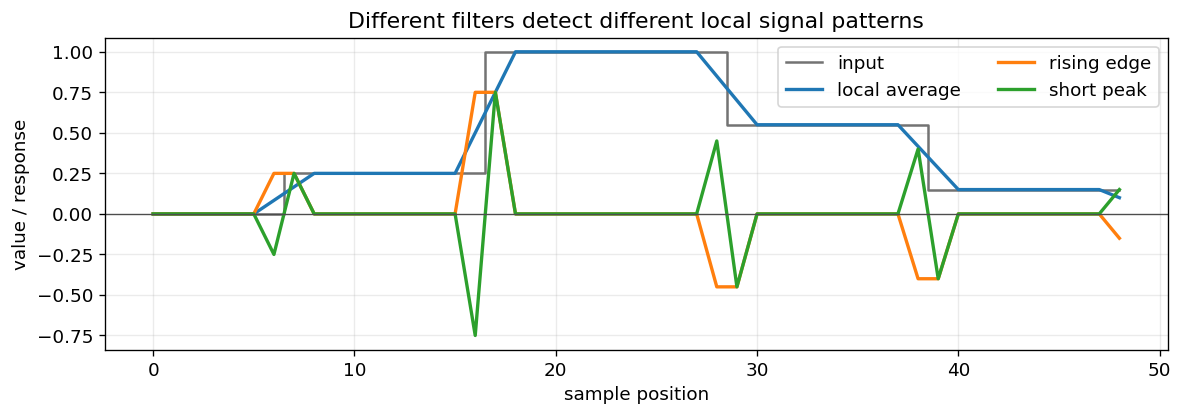

In [3]:
filter_bank_1d = {
    "local average": np.array([1.0, 1.0, 1.0]) / 3,
    "rising edge": np.array([-1.0, 0.0, 1.0]),
    "short peak": np.array([-1.0, 2.0, -1.0]),
}

figure, axis = plt.subplots(figsize=(10, 3.6))
axis.step(np.arange(signal.size), signal, where="mid", color="0.45", label="input")
for name, kernel in filter_bank_1d.items():
    response = same_cross_correlation_1d(signal=signal, kernel=kernel)
    axis.plot(response, linewidth=2, label=name)
axis.axhline(0, color="0.3", linewidth=0.8)
axis.set(xlabel="sample position", ylabel="value / response")
axis.set_title("Different filters detect different local signal patterns")
axis.legend(ncol=2)
axis.grid(alpha=0.25)
figure.tight_layout()

## 2. Extend the same idea to two dimensions

An image is a two-dimensional grid. A $3 \times 3$ filter takes a local
$3 \times 3$ patch, multiplies corresponding entries, and adds them:

$$
R_{i,j} = \sum_{u=0}^{2}\sum_{v=0}^{2}
K_{u,v}\,X_{i+u-1,\,j+v-1}.
$$

The output $R$ is a **feature map**. Every pixel of that map reports how
strongly the local image patch matches the same filter.

Text(0.5, 0.96, 'One 2D filter produces one feature map')

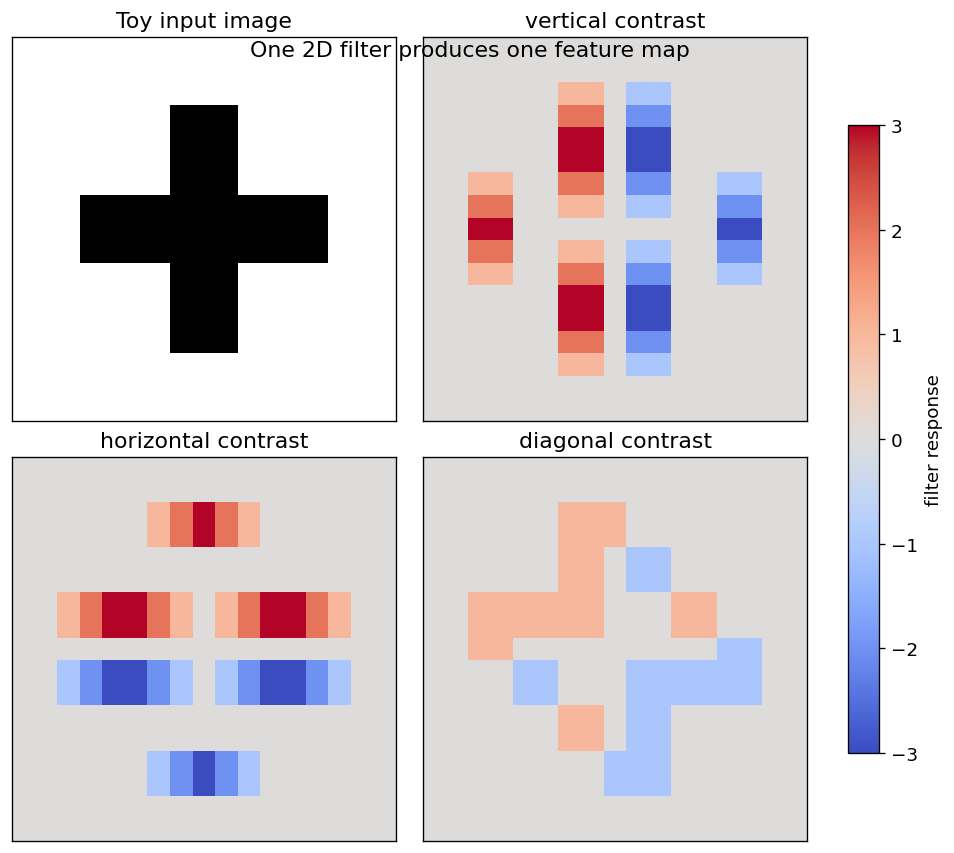

In [4]:
def same_cross_correlation_2d(*, image: np.ndarray, kernel: np.ndarray) -> np.ndarray:
    """Apply an odd-by-odd 2D filter at every image location.

    Args:
        image: Grayscale image with shape `(height, width)`.
        kernel: Odd-by-odd filter with shape `(kernel_height, kernel_width)`.

    Returns:
        Feature map with the same shape as `image`.

    Raises:
        ValueError: If either filter dimension is even.
    """
    if kernel.shape[0] % 2 == 0 or kernel.shape[1] % 2 == 0:
        raise ValueError("Use an odd-by-odd filter so it has a center.")

    row_radius = kernel.shape[0] // 2
    column_radius = kernel.shape[1] // 2
    padded_image = np.pad(
        image,
        pad_width=((row_radius, row_radius), (column_radius, column_radius)),
        mode="constant",
    )
    response = np.empty_like(image, dtype=float)
    for row in range(image.shape[0]):
        for column in range(image.shape[1]):
            local_patch = padded_image[
                row : row + kernel.shape[0],
                column : column + kernel.shape[1],
            ]
            response[row, column] = np.sum(local_patch * kernel)
    return response


toy_image = np.zeros((17, 17))
toy_image[3:14, 7:10] = 1.0
toy_image[7:10, 3:14] = 1.0

vertical_filter = np.array(
    [[-1.0, 0.0, 1.0], [-1.0, 0.0, 1.0], [-1.0, 0.0, 1.0]]
)
horizontal_filter = vertical_filter.T
diagonal_filter = np.array(
    [[-1.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0, 1.0]]
)

filters_2d = {
    "vertical contrast": vertical_filter,
    "horizontal contrast": horizontal_filter,
    "diagonal contrast": diagonal_filter,
}
responses_2d = {
    name: same_cross_correlation_2d(image=toy_image, kernel=kernel)
    for name, kernel in filters_2d.items()
}

response_limit = max(float(np.abs(response).max()) for response in responses_2d.values())
figure, axes = plt.subplots(2, 2, figsize=(8, 7), constrained_layout=True)
axes[0, 0].imshow(toy_image, cmap="gray_r", vmin=0, vmax=1)
axes[0, 0].set_title("Toy input image")
for axis, (name, response) in zip(axes.ravel()[1:], responses_2d.items()):
    image_plot = axis.imshow(
        response,
        cmap="coolwarm",
        vmin=-response_limit,
        vmax=response_limit,
    )
    axis.set_title(name)
for axis in axes.ravel():
    axis.set_xticks([])
    axis.set_yticks([])
figure.colorbar(image_plot, ax=axes.ravel().tolist(), shrink=0.78, label="filter response")
figure.suptitle("One 2D filter produces one feature map", y=0.96)

In [5]:
# A CNN stores many 2D filters together. The leading dimension counts
# output feature maps; the singleton dimension is one grayscale channel.
filter_bank_2d = np.stack(list(filters_2d.values()), axis=0)[:, np.newaxis, :, :]
print(f"One grayscale image: {toy_image.shape}  ->  (height, width)")
print(f"Three-filter bank:   {filter_bank_2d.shape}  ->  (filters, channels, height, width)")

One grayscale image: (17, 17)  ->  (height, width)
Three-filter bank:   (3, 1, 3, 3)  ->  (filters, channels, height, width)


## 3. From hand-designed filters to CNNs

In this notebook, we chose every filter value ourselves. In a CNN, the
filter values are model parameters. Training adjusts them so their feature
maps help reduce prediction error.

Two structural ideas distinguish a convolutional layer from a fully
connected layer:

- **Local receptive field:** a filter initially reads only nearby values or pixels.
- **Weight sharing:** the same learned filter is applied at every position.

The next notebook applies those ideas in a first PyTorch CNN.

[Continue to the MNIST CNN notebook](04-mnist-cnn.ipynb)